**Sel 1: Mount Drive dan cek berkas**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
!ls -lh "{BASE}"
!apt-get install -y unrar > /dev/null 2>&1

Mounted at /content/drive
total 332M
-rw------- 1 root root 282M Nov 22 05:31 GroundTruths_bmpformat.rar
-rw------- 1 root root  51M Nov 22 05:29 GrTh.rar


**Sel 2: Cek isi arsip tanpa mengekstrak**

In [ ]:
!unrar lb "{BASE}/GrTh.rar" | head -30
print("-----")
!unrar lb "{BASE}/GrTh.rar" | wc -l
print("=====")
!unrar lb "{BASE}/GroundTruths_bmpformat.rar" | head -30
print("-----")
!unrar lb "{BASE}/GroundTruths_bmpformat.rar" | wc -l

GrTh/Ground Truth/Basophil/20190526_163027_0.jpg
GrTh/Ground Truth/Basophil/20190526_163414_0.jpg
GrTh/Ground Truth/Basophil/20190526_163446_1.jpg
GrTh/Ground Truth/Basophil/20190526_163532_0.jpg
GrTh/Ground Truth/Basophil/20190526_163545_0.jpg
GrTh/Ground Truth/Basophil/20190526_163608_1.jpg
GrTh/Ground Truth/Basophil/20190526_163656_0.jpg
GrTh/Ground Truth/Basophil/20190526_163721_0.jpg
GrTh/Ground Truth/Basophil/20190526_163735_0.jpg
GrTh/Ground Truth/Basophil/20190526_163753_0.jpg
GrTh/Ground Truth/Basophil/20190526_163806_0.jpg
GrTh/Ground Truth/Basophil/20190526_164040_0.jpg
GrTh/Ground Truth/Basophil/20190526_164053_0.jpg
GrTh/Ground Truth/Basophil/20190526_164136_0.jpg
GrTh/Ground Truth/Basophil/20190526_164157_0.jpg
GrTh/Ground Truth/Basophil/20190526_164453_0.jpg
GrTh/Ground Truth/Basophil/20190526_164621_0.jpg
GrTh/Ground Truth/Basophil/20190526_164638_0.jpg
GrTh/Ground Truth/Basophil/20190526_164646_0.jpg
GrTh/Ground Truth/Basophil/20190526_164729_0.jpg
GrTh/Ground Truth/Ba

**Sel 3: Ekstrak ke disk lokal Colab**

In [ ]:
!mkdir -p /content/raabin_gt/grth /content/raabin_gt/bmp
!unrar x -inul "{BASE}/GrTh.rar" /content/raabin_gt/grth/
!unrar x -inul "{BASE}/GroundTruths_bmpformat.rar" /content/raabin_gt/bmp/

**Sel 4: Ringkasan struktur**

In [ ]:
import os, collections

for root in ["/content/raabin_gt/grth", "/content/raabin_gt/bmp"]:
    print("=" * 60, "\n", root)
    ext = collections.Counter()
    folders = collections.Counter()
    for dp, dn, fn in os.walk(root):
        for f in fn:
            ext[os.path.splitext(f)[1].lower()] += 1
            folders[os.path.relpath(dp, root)] += 1
    print("Ekstensi:", dict(ext))
    print("Berkas per folder:")
    for k, v in sorted(folders.items())[:20]:
        print(f"  {k}: {v}")
    print("Contoh nama berkas:")
    shown = 0
    for dp, dn, fn in os.walk(root):
        for f in sorted(fn)[:5]:
            print("  ", os.path.relpath(os.path.join(dp, f), root))
        shown += 1
        if shown >= 4: break

 /content/raabin_gt/grth
Ekstensi: {'.jpg': 2290}
Berkas per folder:
  GrTh/Ground Truth/Basophil: 218
  GrTh/Ground Truth/Eosinophil: 201
  GrTh/Ground Truth/Lymphocyte: 242
  GrTh/Ground Truth/Monocyte: 242
  GrTh/Ground Truth/Neutrophil: 242
  GrTh/Original/Basophil: 218
  GrTh/Original/Eosinophil: 201
  GrTh/Original/Lymphocyte: 242
  GrTh/Original/Monocyte: 242
  GrTh/Original/Neutrophil: 242
Contoh nama berkas:
   GrTh/Ground Truth/Eosinophil/95-5-10-1_178_2.jpg
   GrTh/Ground Truth/Eosinophil/95-5-10-1_223_5.jpg
   GrTh/Ground Truth/Eosinophil/95-5-10-1_654_1.jpg
   GrTh/Ground Truth/Eosinophil/95-5-11-1_51_1.jpg
   GrTh/Ground Truth/Eosinophil/95-5-4-1_45_1.jpg
 /content/raabin_gt/bmp
Ekstensi: {'.bmp': 2290}
Berkas per folder:
  Test_GT_bmp: 233
  Test_bmp: 233
  Train_GT_bmp: 912
  Train_bmp: 912
Contoh nama berkas:
   Train_bmp/20190526_163414_0.bmp
   Train_bmp/20190526_163446_1.bmp
   Train_bmp/20190526_163532_0.bmp
   Train_bmp/20190526_163608_1.bmp
   Train_bmp/20190526_

**Sel 5: Cek lanjutan**

In [ ]:
import os, re, collections, random
import numpy as np
from PIL import Image

G = "/content/raabin_gt"
bmp = f"{G}/bmp"

# 1) Pasangan citra-masker dan pola nama
rows = []
for s in ["Train", "Test"]:
    imgs = sorted(os.listdir(f"{bmp}/{s}_bmp"))
    gts  = set(os.listdir(f"{bmp}/{s}_GT_bmp"))
    print(s, "citra:", len(imgs), "| masker cocok:", sum(i in gts for i in imgs))
    for n in imgs:
        pola = "A_timestamp" if re.match(r"^\d{8}_\d{6}_\d+", n) else "B_lainnya"
        w, h = Image.open(f"{bmp}/{s}_bmp/{n}").size
        rows.append((s, pola, (w, h), n))

print("\nSplit x pola nama x resolusi:")
for k, v in sorted(collections.Counter((r[0], r[1], r[2]) for r in rows).items(), key=str):
    print(" ", k, v)

# 2) Nilai piksel masker (cek 30 masker acak)
random.seed(42)
sample = random.sample(rows, 30)
vals = collections.Counter()
for s, pola, size, n in sample:
    m = np.array(Image.open(f"{bmp}/{s}_GT_bmp/{n}"))
    vals[(m.ndim, m.shape[-1] if m.ndim == 3 else 1)] += 1
    print(n, "shape:", m.shape, "nilai unik:", np.unique(m.reshape(-1, m.shape[-1]) if m.ndim == 3 else m, axis=0)[:6].tolist())
    if len(vals) > 0 and sum(vals.values()) >= 5: break

# 3) Kecocokan nama dengan GrTh (untuk label jenis sel)
cls = {}
for c in os.listdir(f"{G}/grth/GrTh/Original"):
    for f in os.listdir(f"{G}/grth/GrTh/Original/{c}"):
        cls[os.path.splitext(f)[0]] = c
stems = [os.path.splitext(r[3])[0] for r in rows]
print("\nNama BMP yang ketemu di GrTh:", sum(s in cls for s in stems), "dari", len(stems))
print("Jumlah citra asal unik (tanpa indeks sel):",
      len({s.rsplit('_', 1)[0] for s in stems}))

Train citra: 912 | masker cocok: 912
Test citra: 233 | masker cocok: 233

Split x pola nama x resolusi:
  ('Test', 'A_timestamp', (575, 575)) 45
  ('Test', 'B_lainnya', (575, 575)) 188
  ('Train', 'A_timestamp', (575, 575)) 173
  ('Train', 'B_lainnya', (575, 575)) 739
95-5-11-1_96_1.bmp shape: (575, 575) nilai unik: [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

**Sel 6: Verifikasi**

In [ ]:
import os, re, random, collections
import numpy as np
from PIL import Image

G = "/content/raabin_gt"; bmp = f"{G}/bmp"

# label kelas dari GrTh
cls = {}
for c in os.listdir(f"{G}/grth/GrTh/Original"):
    for f in os.listdir(f"{G}/grth/GrTh/Original/{c}"):
        cls[os.path.splitext(f)[0]] = c

recs = []
for s in ["Train", "Test"]:
    for n in sorted(os.listdir(f"{bmp}/{s}_bmp")):
        st = os.path.splitext(n)[0]
        pola = "A" if re.match(r"^\d{8}_\d{6}_\d+$", st) else "B"
        recs.append(dict(split=s, name=n, stem=st, pola=pola, cls=cls[st]))

# 1) Pola nama x jenis sel (kunci untuk dugaan basofil)
print("Pola x kelas:")
for k, v in sorted(collections.Counter((r["pola"], r["cls"]) for r in recs).items()):
    print(" ", k, v)

# 2) Nilai piksel masker: 8 contoh, tampilkan 6 nilai terbanyak
def top_vals(path, k=6):
    m = np.array(Image.open(path))
    shp = m.shape
    if m.ndim == 3:
        m = m[..., 0]
    cnt = np.bincount(m.ravel(), minlength=256)
    top = [(int(i), int(cnt[i])) for i in np.argsort(cnt)[::-1][:k] if cnt[i] > 0]
    return shp, top

random.seed(42)
print("\nMasker BMP (nilai, jumlah piksel):")
for r in random.sample(recs, 8):
    print(" ", r["name"], r["cls"], top_vals(f"{bmp}/{r['split']}_GT_bmp/{r['name']}"))

print("\nMasker GrTh JPG (untuk perbandingan):")
for r in random.sample(recs, 3):
    p = f"{G}/grth/GrTh/Ground Truth/{r['cls']}/{r['stem']}.jpg"
    print(" ", r["stem"], top_vals(p))

# 3) Statistik warna rata-rata per pola (indikasi perbedaan domain)
print("\nRerata RGB citra asli per pola:")
for pola in ["A", "B"]:
    sub = [r for r in recs if r["pola"] == pola]
    sub = random.sample(sub, min(40, len(sub)))
    arr = np.stack([np.array(Image.open(f"{bmp}/{r['split']}_bmp/{r['name']}").convert("RGB")).reshape(-1, 3).mean(0) for r in sub])
    print(" ", pola, "mean RGB:", arr.mean(0).round(1).tolist(), "| SD antar citra:", arr.std(0).round(1).tolist())

Pola x kelas:
  ('A', 'Basophil') 218
  ('B', 'Eosinophil') 201
  ('B', 'Lymphocyte') 242
  ('B', 'Monocyte') 242
  ('B', 'Neutrophil') 242

Masker BMP (nilai, jumlah piksel):
  95-5-11-1_96_1.bmp Monocyte ((575, 575), [(0, 255101), (255, 40680), (100, 34844)])
  20190527_112437_0.bmp Basophil ((575, 575), [(0, 271945), (255, 58680)])
  95-8-20-3_144_1.bmp Eosinophil ((575, 575), [(0, 275901), (255, 36286), (100, 18438)])
  95-8-13-4_153_1.bmp Lymphocyte ((575, 575), [(0, 308116), (100, 18469), (255, 4040)])
  95-8-12-5_27_2.bmp Neutrophil ((575, 575), [(0, 279087), (255, 33162), (100, 18376)])
  95-8-1-1_425_1.bmp Neutrophil ((575, 575), [(0, 281752), (255, 33136), (100, 15737)])
  95-5-10-1_93_1.bmp Neutrophil ((575, 575), [(0, 282018), (255, 29657), (100, 18950)])
  95-9-1-2_94_1.bmp Monocyte ((575, 575), [(0, 256222), (255, 37540), (100, 36863)])

Masker GrTh JPG (untuk perbandingan):
  95-5-10-1_162_6 ((575, 575, 3), [(0, 270081), (255, 29108), (100, 24740), (254, 1135), (253, 717

**Sel 7: Verifikasi lanjutan**

Nilai unik masker per kelas:
  Basophil {(0, 255): 218}
  Lymphocyte {(0, 100, 255): 242}
  Neutrophil {(0, 100, 255): 242}
  Monocyte {(0, 100, 255): 242}
  Eosinophil {(0, 100, 255): 201}

Sel per batch: {'95-5': 88, '95-7': 17, '95-8': 725, '95-9': 97}
Jumlah apusan unik (pola B): 54
Batch x kelas:
  ('95-5', 'Eosinophil') 7
  ('95-5', 'Lymphocyte') 26
  ('95-5', 'Monocyte') 29
  ('95-5', 'Neutrophil') 26
  ('95-7', 'Eosinophil') 3
  ('95-7', 'Lymphocyte') 9
  ('95-7', 'Monocyte') 4
  ('95-7', 'Neutrophil') 1
  ('95-8', 'Eosinophil') 179
  ('95-8', 'Lymphocyte') 170
  ('95-8', 'Monocyte') 184
  ('95-8', 'Neutrophil') 192
  ('95-9', 'Eosinophil') 12
  ('95-9', 'Lymphocyte') 37
  ('95-9', 'Monocyte') 25
  ('95-9', 'Neutrophil') 23

Rerata RGB per batch:
  95-5 88 sel | mean RGB: [174.5, 131.2, 144.5]
  95-7 17 sel | mean RGB: [184.9, 139.8, 152.6]
  95-8 725 sel | mean RGB: [180.9, 138.4, 150.8]
  95-9 97 sel | mean RGB: [178.7, 136.0, 149.1]


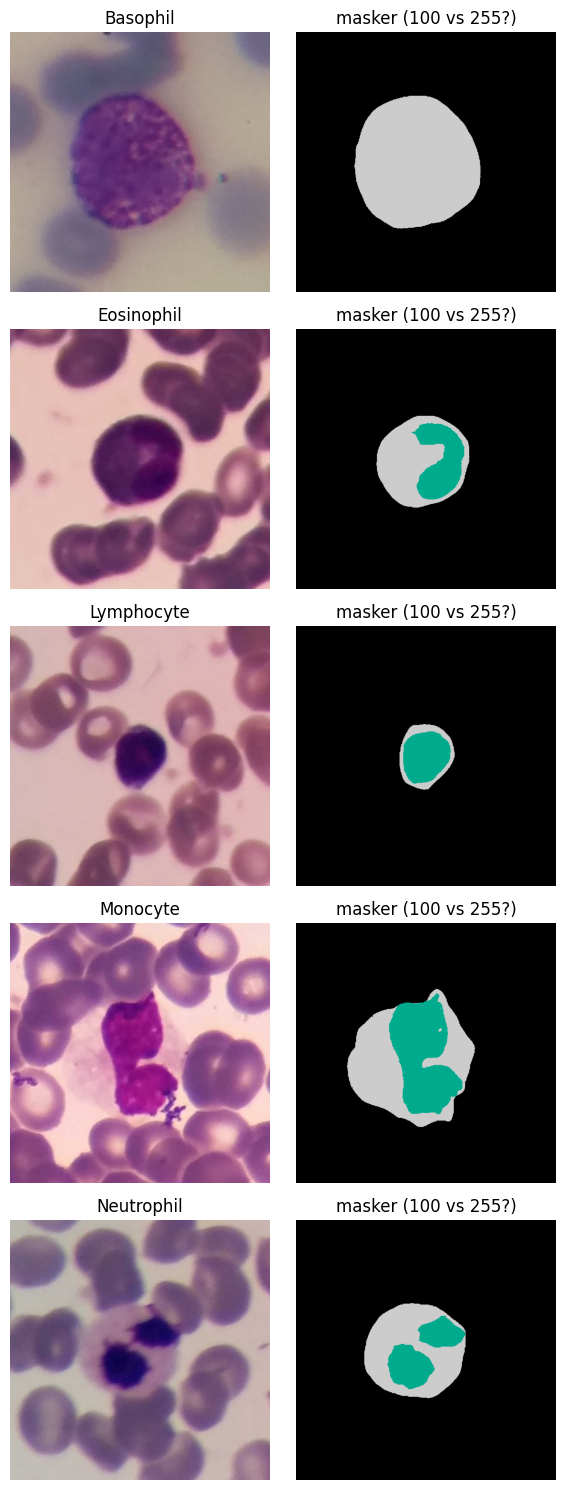

In [ ]:
import matplotlib.pyplot as plt

# 1) Nilai unik di SEMUA 1145 masker BMP, per kelas
stat = collections.defaultdict(collections.Counter)
for r in recs:
    m = np.array(Image.open(f"{bmp}/{r['split']}_GT_bmp/{r['name']}"))
    if m.ndim == 3: m = m[..., 0]
    stat[r["cls"]][tuple(int(v) for v in np.unique(m))] += 1
print("Nilai unik masker per kelas:")
for c, cnt in stat.items():
    print(" ", c, dict(cnt))

# 2) Struktur batch di pola B (awalan nama = kode apusan/tanggal?)
B = [r for r in recs if r["pola"] == "B"]
for r in B:
    r["smear"] = r["stem"].split("_")[0]
    r["batch"] = "-".join(r["smear"].split("-")[:2])
print("\nSel per batch:", dict(collections.Counter(r["batch"] for r in B)))
print("Jumlah apusan unik (pola B):", len({r["smear"] for r in B}))
print("Batch x kelas:")
for k, v in sorted(collections.Counter((r["batch"], r["cls"]) for r in B).items()):
    print(" ", k, v)

# 3) Warna rata-rata per batch
random.seed(42)
print("\nRerata RGB per batch:")
for b in sorted({r["batch"] for r in B}):
    pool = [r for r in B if r["batch"] == b]
    sub = random.sample(pool, min(30, len(pool)))
    arr = np.stack([np.array(Image.open(f"{bmp}/{r['split']}_bmp/{r['name']}").convert("RGB")).reshape(-1, 3).mean(0) for r in sub])
    print(" ", b, len(pool), "sel | mean RGB:", arr.mean(0).round(1).tolist())

# 4) Visual: citra dan masker tiap kelas
fig, ax = plt.subplots(5, 2, figsize=(6, 15))
for i, c in enumerate(["Basophil", "Eosinophil", "Lymphocyte", "Monocyte", "Neutrophil"]):
    r = next(x for x in recs if x["cls"] == c)
    ax[i, 0].imshow(Image.open(f"{bmp}/{r['split']}_bmp/{r['name']}")); ax[i, 0].set_title(c)
    m = np.array(Image.open(f"{bmp}/{r['split']}_GT_bmp/{r['name']}"))
    if m.ndim == 3: m = m[..., 0]
    ax[i, 1].imshow(m, cmap="nipy_spectral"); ax[i, 1].set_title("masker (100 vs 255?)")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()

**Sel 8: Pelabelan, split, pemeriksaan kebocoran, dan verifikasi visual**

927 sel | 54 apusan | kelas: {'Lymphocyte': 242, 'Neutrophil': 242, 'Monocyte': 242, 'Eosinophil': 201}
Semua masker valid (hanya 0/100/255).

[grouped] train=673 val=181 test=73
  kelas test: {'Neutrophil': 24, 'Monocyte': 22, 'Lymphocyte': 22, 'Eosinophil': 5}

[random] train=648 val=139 test=140
  kelas test: {'Monocyte': 49, 'Lymphocyte': 36, 'Neutrophil': 31, 'Eosinophil': 24}

[cross_session] train=418 val=229 test=202
  kelas test: {'Lymphocyte': 72, 'Monocyte': 58, 'Neutrophil': 50, 'Eosinophil': 22}

=== Pemeriksaan kebocoran (train vs test) ===
[grouped] apusan sama: 0 | citra asal sama: 0 | pHash jarak<=6: 0 dari 73 (min=14)
[random] apusan sama: 45 | citra asal sama: 6 | pHash jarak<=6: 0 dari 140 (min=12)
[cross_session] apusan sama: 0 | citra asal sama: 0 | pHash jarak<=6: 0 dari 202 (min=12)


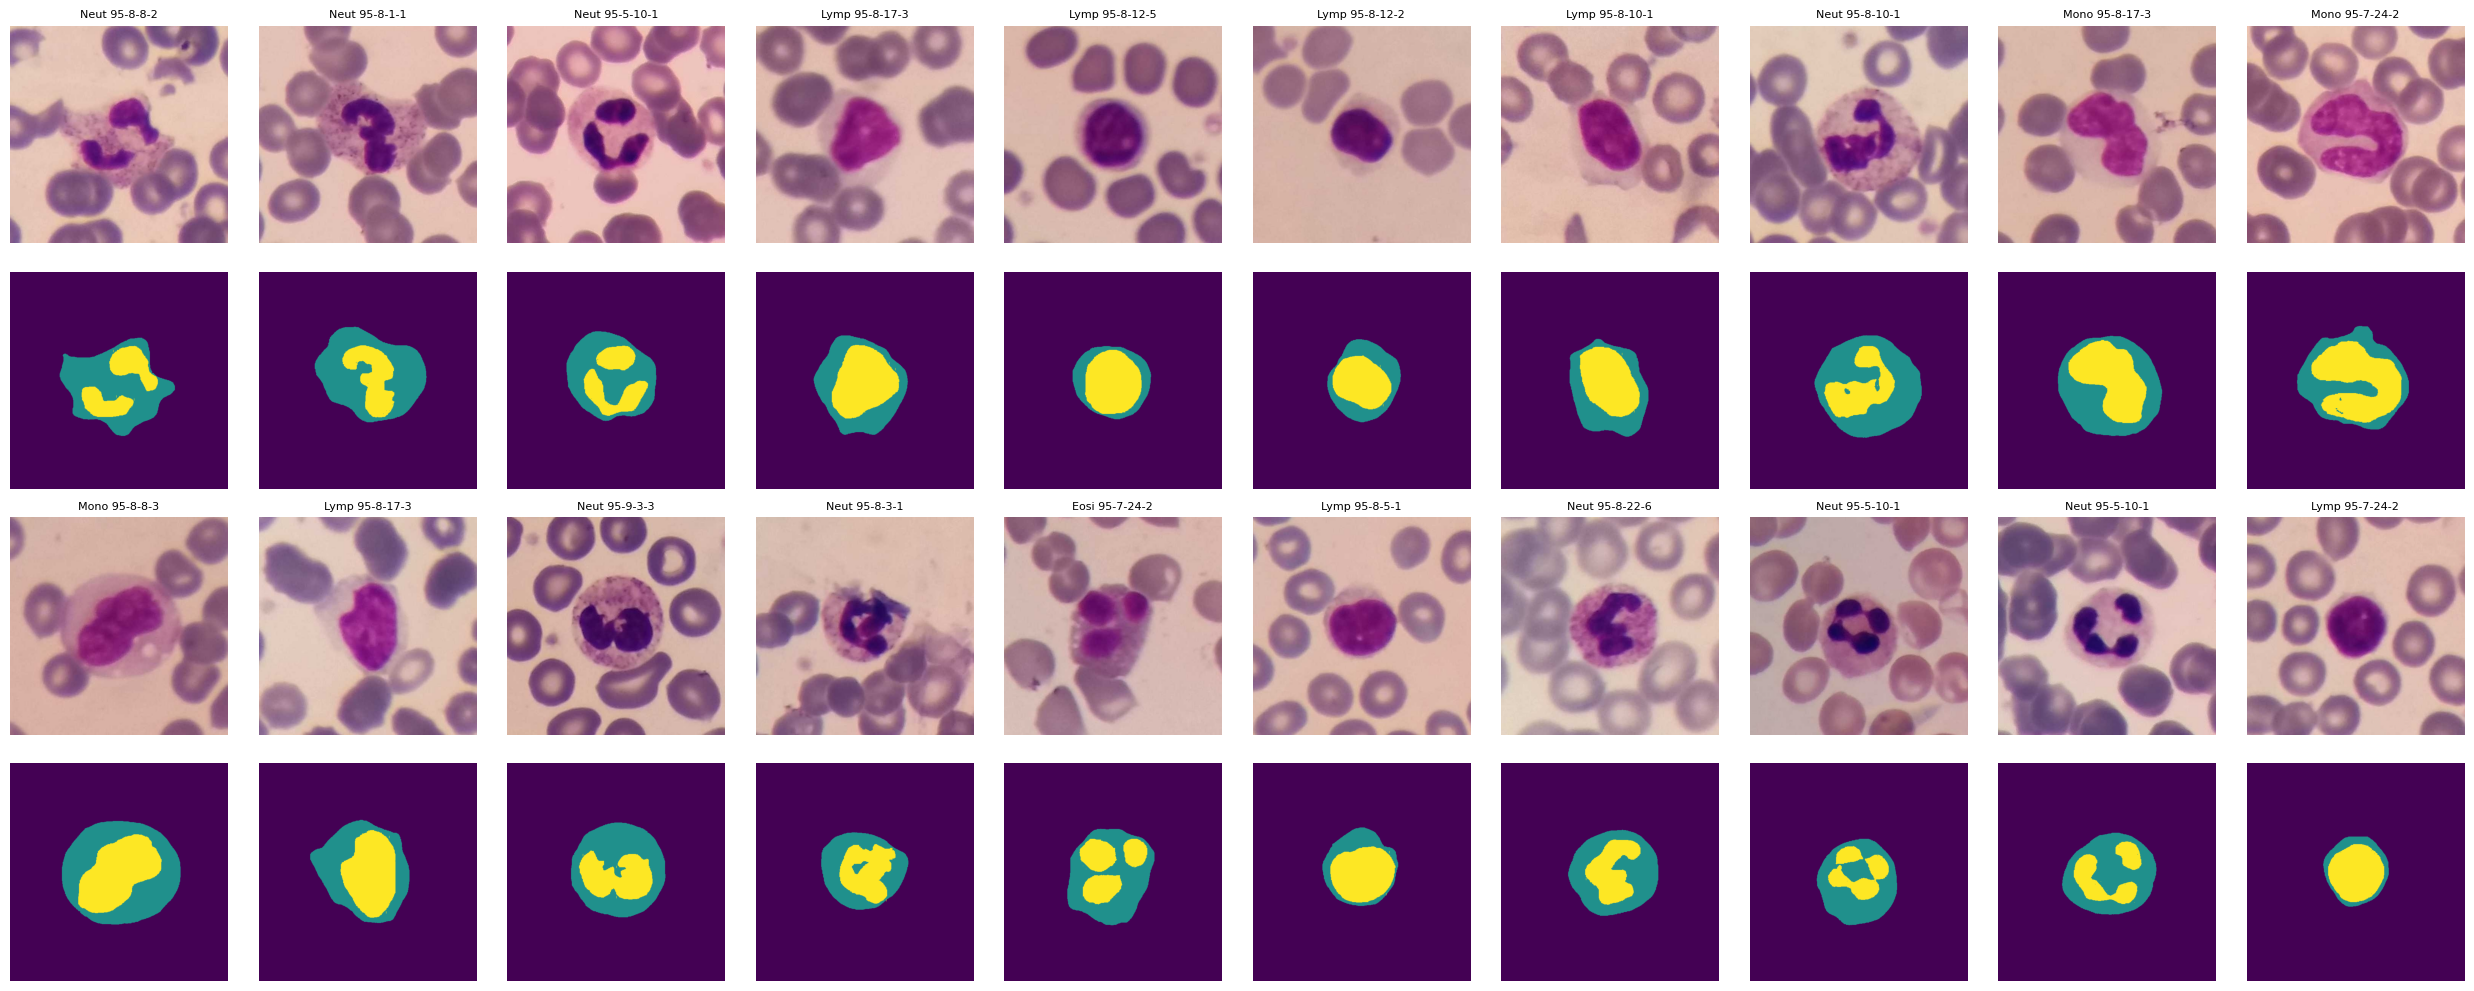

In [ ]:
!pip -q install imagehash
import os, re, random, numpy as np, pandas as pd, imagehash, matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit, train_test_split

DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
G = "/content/raabin_gt"; bmp = f"{G}/bmp"
os.makedirs(f"{DRIVE}/splits", exist_ok=True)
SEED = 42

# 1) Tabel data: hanya pola B (tanpa basofil)
df = pd.DataFrame([r for r in recs if r["pola"] == "B"])
df["img"]   = df.apply(lambda r: f"{bmp}/{r['split']}_bmp/{r['name']}", axis=1)
df["mask"]  = df.apply(lambda r: f"{bmp}/{r['split']}_GT_bmp/{r['name']}", axis=1)
df["smear"] = df.stem.str.split("_").str[0]
df["batch"] = df.smear.str.split("-").str[:2].str.join("-")
df["image_id"] = df.stem.str.rsplit("_", n=1).str[0]   # citra asal (tanpa indeks sel)
print(len(df), "sel |", df.smear.nunique(), "apusan | kelas:", df.cls.value_counts().to_dict())

# 2) Konversi masker: 0=latar, 1=sitoplasma(255), 2=nukleus(100)
def load_mask(p):
    m = np.array(Image.open(p))
    if m.ndim == 3: m = m[..., 0]
    assert set(np.unique(m)) <= {0, 100, 255}, np.unique(m)
    out = np.zeros(m.shape, np.uint8); out[m == 255] = 1; out[m == 100] = 2
    return out
for p in df["mask"]: load_mask(p)          # cek semua 927 masker valid
print("Semua masker valid (hanya 0/100/255).")

# 3) Tiga skema split (seed 42)
def grp_split(d, seed=SEED, frac=0.15):
    a, te = next(GroupShuffleSplit(1, test_size=frac, random_state=seed).split(d, groups=d.smear))
    d1 = d.iloc[a]
    b, va = next(GroupShuffleSplit(1, test_size=frac/(1-frac), random_state=seed).split(d1, groups=d1.smear))
    return d1.iloc[b], d1.iloc[va], d.iloc[te]

splits = {}
splits["grouped"] = grp_split(df)
trv, te = train_test_split(df, test_size=0.15, random_state=SEED)
tr, va = train_test_split(trv, test_size=0.15/0.85, random_state=SEED)
splits["random"] = (tr, va, te)
d95 = df[df.batch == "95-8"]
a, b = grp_split(d95)[:2]
splits["cross_session"] = (a, b, df[df.batch != "95-8"])

for name, (tr, va, te) in splits.items():
    print(f"\n[{name}] train={len(tr)} val={len(va)} test={len(te)}")
    print("  kelas test:", te.cls.value_counts().to_dict())
    for part, d in zip(["train", "val", "test"], [tr, va, te]):
        d[["name", "stem", "cls", "smear", "batch", "image_id"]].to_csv(f"{DRIVE}/splits/{name}_{part}.csv", index=False)

# 4) Pemeriksaan kebocoran: apusan, citra asal, dan perceptual hash
df["phash"] = [imagehash.phash(Image.open(p).convert("RGB")) for p in df["img"]]
print("\n=== Pemeriksaan kebocoran (train vs test) ===")
for name, (tr, va, te) in splits.items():
    sm = len(set(tr.smear) & set(te.smear)); im = len(set(tr.image_id) & set(te.image_id))
    trh = df.loc[tr.index, "phash"].tolist()
    dmin = [min(h - x for x in trh) for h in df.loc[te.index, "phash"]]
    print(f"[{name}] apusan sama: {sm} | citra asal sama: {im} | "
          f"pHash jarak<=6: {sum(d <= 6 for d in dmin)} dari {len(dmin)} (min={min(dmin)})")

# 5) Verifikasi visual 20 citra (wajib di Kisi-Kisi)
random.seed(SEED); pick = random.sample(range(len(df)), 20)
fig, ax = plt.subplots(4, 10, figsize=(25, 10))
for k, i in enumerate(pick):
    r = df.iloc[i]; x = np.array(Image.open(r.img).convert("RGB")); m = load_mask(r["mask"])
    a1, a2 = ax[(k // 10) * 2, k % 10], ax[(k // 10) * 2 + 1, k % 10]
    a1.imshow(x); a1.set_title(f"{r.cls[:4]} {r.smear}", fontsize=8)
    a2.imshow(m, cmap="viridis", vmin=0, vmax=2)
    a1.axis("off"); a2.axis("off")
plt.tight_layout(); plt.savefig(f"{DRIVE}/verifikasi_20_citra.png", dpi=80); plt.show()

**Sel 8b: bangun ulang split**

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
import pandas as pd

def sgk_split(d, seed=SEED, n_test=7, n_val=6):
    # ~1/7 test, ~1/6 sisanya val; stratifikasi kelas; grup = apusan
    tr_i, te_i = next(StratifiedGroupKFold(n_test, shuffle=True, random_state=seed)
                      .split(d, d.cls.values, d.smear.values))
    d1, te = d.iloc[tr_i], d.iloc[te_i]
    a_i, v_i = next(StratifiedGroupKFold(n_val, shuffle=True, random_state=seed)
                    .split(d1, d1.cls.values, d1.smear.values))
    return d1.iloc[a_i], d1.iloc[v_i], te

splits = {}
# 1) grouped
tr, va, te = sgk_split(df)
splits["grouped"] = dict(train=tr, val=va, test=te)
# 2) random: ukuran disamakan dengan grouped agar ablasi hanya mengubah satu faktor
trv, te_r = train_test_split(df, test_size=len(te), stratify=df.cls, random_state=SEED)
tr_r, va_r = train_test_split(trv, test_size=len(va), stratify=trv.cls, random_state=SEED)
splits["random"] = dict(train=tr_r, val=va_r, test=te_r)
# 3) cross_session: latih di batch 95-8, uji dalam-sesi dan lintas-sesi
d95 = df[df.batch == "95-8"]
tr_c, va_c, te_in = sgk_split(d95)
splits["cross_session"] = dict(train=tr_c, val=va_c, test_insession=te_in, test=df[df.batch != "95-8"])

cols = ["name", "stem", "cls", "smear", "batch", "image_id"]
for name, parts in splits.items():
    print(f"\n[{name}]", {p: len(d) for p, d in parts.items()})
    for p, d in parts.items():
        d[cols].to_csv(f"{DRIVE}/splits/{name}_{p}.csv", index=False)
        print(f"   {p:15s}", d.cls.value_counts().to_dict())

# Pemeriksaan kebocoran ulang (setiap bagian uji vs train)
print("\n=== Kebocoran (train vs bagian uji) ===")
for name, parts in splits.items():
    trh = df.loc[parts["train"].index, "phash"].tolist()
    for p in [k for k in parts if k.startswith("test")]:
        te_ = parts[p]
        dmin = [min(h - x for x in trh) for h in df.loc[te_.index, "phash"]]
        print(f"[{name}/{p}] apusan sama: {len(set(parts['train'].smear) & set(te_.smear))} | "
              f"citra asal sama: {len(set(parts['train'].image_id) & set(te_.image_id))} | "
              f"pHash<=6: {sum(d <= 6 for d in dmin)}/{len(dmin)} (min={min(dmin)})")


[grouped] {'train': 728, 'val': 91, 'test': 108}
   train           {'Neutrophil': 195, 'Monocyte': 184, 'Eosinophil': 181, 'Lymphocyte': 168}
   val             {'Lymphocyte': 43, 'Monocyte': 25, 'Neutrophil': 16, 'Eosinophil': 7}
   test            {'Monocyte': 33, 'Lymphocyte': 31, 'Neutrophil': 31, 'Eosinophil': 13}

[random] {'train': 728, 'val': 91, 'test': 108}
   train           {'Monocyte': 190, 'Lymphocyte': 190, 'Neutrophil': 190, 'Eosinophil': 158}
   val             {'Monocyte': 24, 'Lymphocyte': 24, 'Neutrophil': 24, 'Eosinophil': 19}
   test            {'Monocyte': 28, 'Lymphocyte': 28, 'Neutrophil': 28, 'Eosinophil': 24}

[cross_session] {'train': 642, 'val': 64, 'test_insession': 19, 'test': 202}
   train           {'Eosinophil': 171, 'Neutrophil': 170, 'Monocyte': 163, 'Lymphocyte': 138}
   val             {'Lymphocyte': 23, 'Monocyte': 18, 'Neutrophil': 16, 'Eosinophil': 7}
   test_insession  {'Lymphocyte': 9, 'Neutrophil': 6, 'Monocyte': 3, 'Eosinophil': 1}
   test

**Sel 8c: perbaiki cross_session**

In [ ]:
d95 = df[df.batch == "95-8"]
tr_c, va_c, te_in = sgk_split(d95, n_test=5, n_val=6)   # uji dalam-sesi ~20%
splits["cross_session"] = dict(train=tr_c, val=va_c, test_insession=te_in, test=df[df.batch != "95-8"])

for p, d in splits["cross_session"].items():
    d[cols].to_csv(f"{DRIVE}/splits/cross_session_{p}.csv", index=False)
    print(f"{p:15s} n={len(d):4d}", d.cls.value_counts().to_dict())

trh = df.loc[tr_c.index, "phash"].tolist()
for p in ["test_insession", "test"]:
    te_ = splits["cross_session"][p]
    dmin = [min(h - x for x in trh) for h in df.loc[te_.index, "phash"]]
    print(f"[cross_session/{p}] apusan sama: {len(set(tr_c.smear) & set(te_.smear))} | "
          f"citra asal sama: {len(set(tr_c.image_id) & set(te_.image_id))} | "
          f"pHash<=6: {sum(d <= 6 for d in dmin)}/{len(dmin)} (min={min(dmin)})")

train           n= 509 {'Eosinophil': 165, 'Monocyte': 115, 'Lymphocyte': 115, 'Neutrophil': 114}
val             n= 147 {'Monocyte': 50, 'Neutrophil': 49, 'Lymphocyte': 41, 'Eosinophil': 7}
test_insession  n=  69 {'Neutrophil': 29, 'Monocyte': 19, 'Lymphocyte': 14, 'Eosinophil': 7}
test            n= 202 {'Lymphocyte': 72, 'Monocyte': 58, 'Neutrophil': 50, 'Eosinophil': 22}
[cross_session/test_insession] apusan sama: 0 | citra asal sama: 0 | pHash<=6: 0/69 (min=12)
[cross_session/test] apusan sama: 0 | citra asal sama: 0 | pHash<=6: 0/202 (min=12)


**Sel 9: EDA**

Jumlah citra: 927 | apusan: 54
Kelas: {'Lymphocyte': 242, 'Neutrophil': 242, 'Monocyte': 242, 'Eosinophil': 201}
Objek per citra (komponen terhubung): {1: 908, 2: 13, 3: 6}

Ukuran piksel per kelas (median):
            area_cell  area_nuc  area_cyto  nc_ratio
cls                                                 
Eosinophil    56250.0   20182.0    36615.0     0.353
Lymphocyte    30450.0   18684.0    10954.0     0.630
Monocyte      70290.0   32067.0    38113.5     0.454
Neutrophil    48635.0   16089.0    31937.5     0.335

Sel per apusan: min/median/maks = [2.0, 9.0, 139.0]


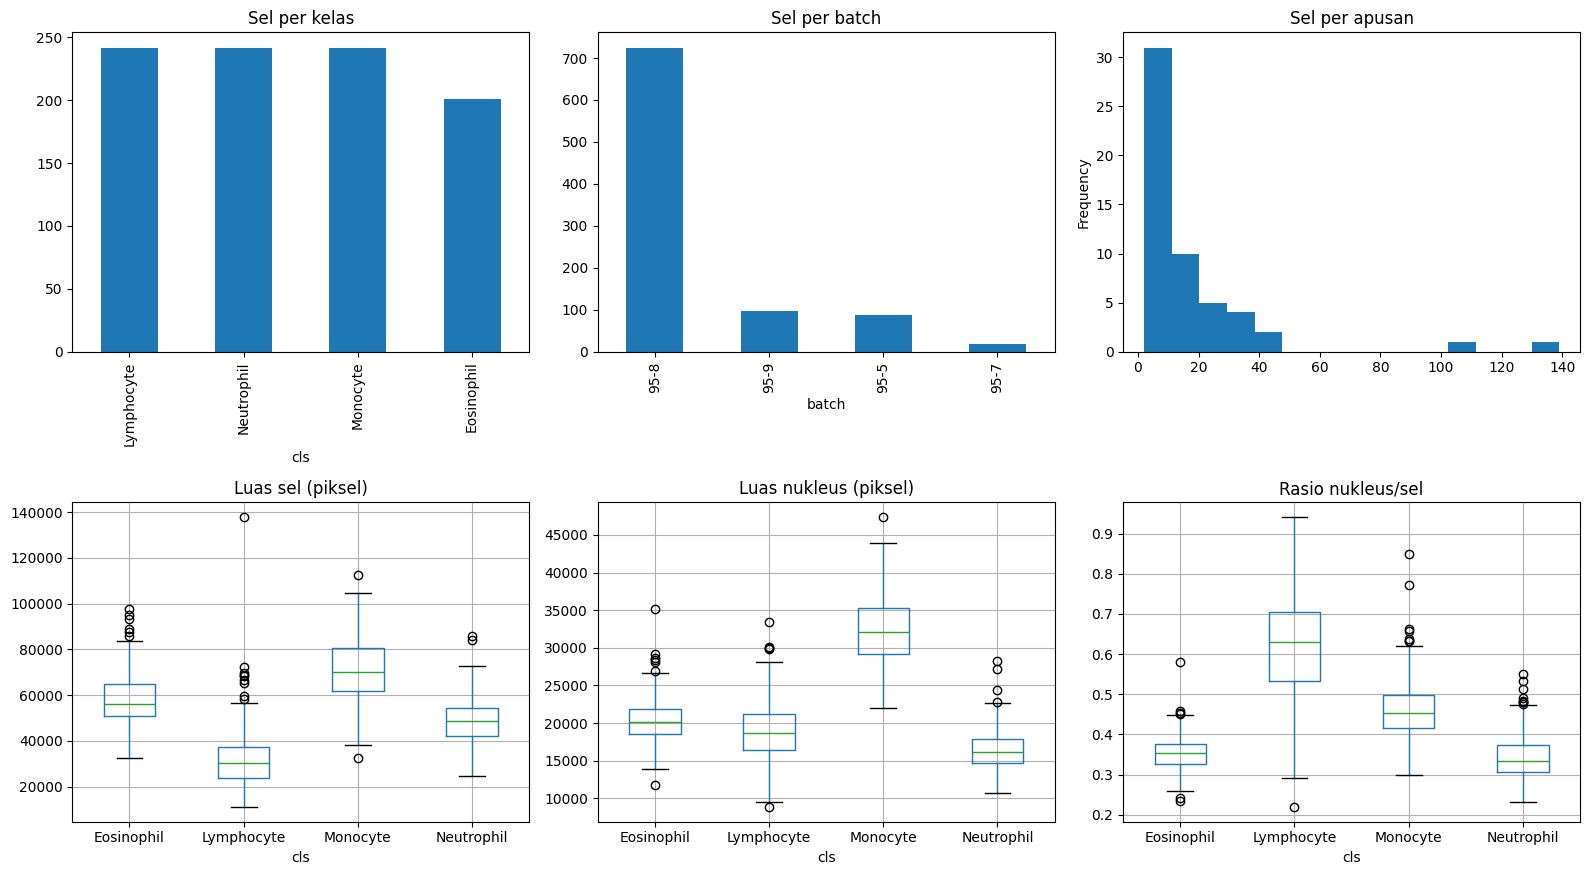

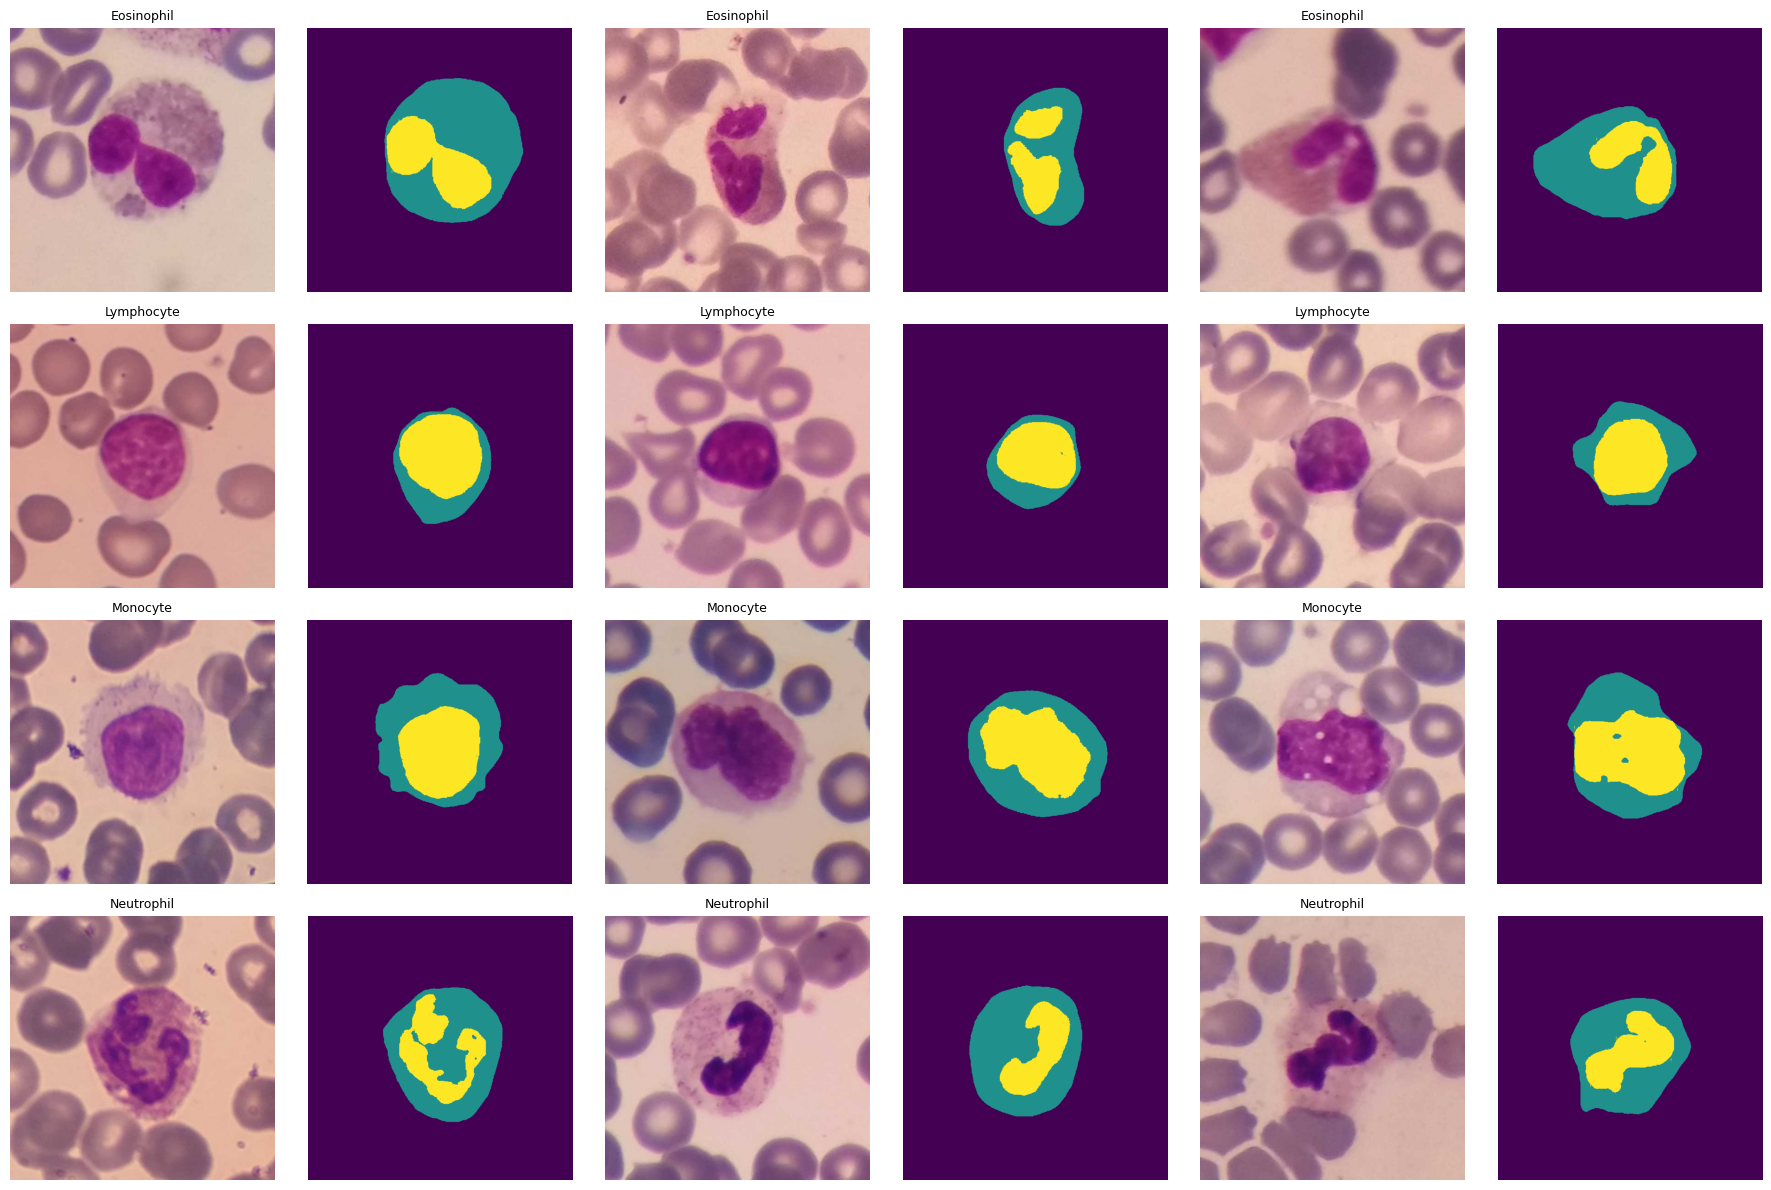

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy import ndimage
EDA = f"{DRIVE}/eda"; os.makedirs(EDA, exist_ok=True)

rows = []
for r in df.itertuples():
    m = load_mask(r.mask)
    nuc, cyt = int((m == 2).sum()), int((m == 1).sum()); cell = nuc + cyt
    n_obj = ndimage.label(m > 0)[1]
    rows.append(dict(name=r.name, cls=r.cls, smear=r.smear, batch=r.batch, n_objek=n_obj,
                     area_cell=cell, area_nuc=nuc, area_cyto=cyt,
                     nc_ratio=nuc / cell if cell else np.nan, frac_img=cell / m.size))
eda = pd.DataFrame(rows); eda.to_csv(f"{EDA}/eda_per_sel.csv", index=False)

print("Jumlah citra:", len(eda), "| apusan:", eda.smear.nunique())
print("Kelas:", eda.cls.value_counts().to_dict())
print("Objek per citra (komponen terhubung):", eda.n_objek.value_counts().to_dict())
print("\nUkuran piksel per kelas (median):")
print(eda.groupby("cls")[["area_cell", "area_nuc", "area_cyto", "nc_ratio"]].median().round(3))
print("\nSel per apusan: min/median/maks =", eda.groupby("smear").size().agg(["min", "median", "max"]).tolist())

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
eda.cls.value_counts().plot.bar(ax=ax[0, 0], title="Sel per kelas")
eda.batch.value_counts().plot.bar(ax=ax[0, 1], title="Sel per batch")
eda.groupby("smear").size().plot.hist(bins=15, ax=ax[0, 2], title="Sel per apusan")
eda.boxplot("area_cell", by="cls", ax=ax[1, 0]); ax[1, 0].set_title("Luas sel (piksel)")
eda.boxplot("area_nuc", by="cls", ax=ax[1, 1]); ax[1, 1].set_title("Luas nukleus (piksel)")
eda.boxplot("nc_ratio", by="cls", ax=ax[1, 2]); ax[1, 2].set_title("Rasio nukleus/sel")
plt.suptitle(""); plt.tight_layout(); plt.savefig(f"{EDA}/eda_ringkas.png", dpi=100); plt.show()

# Contoh visual: 3 sel per kelas
fig, ax = plt.subplots(4, 6, figsize=(18, 12))
for j, c in enumerate(["Eosinophil", "Lymphocyte", "Monocyte", "Neutrophil"]):
    for k, r in enumerate(df[df.cls == c].sample(3, random_state=42).itertuples()):
        ax[j, k * 2].imshow(Image.open(r.img).convert("RGB")); ax[j, k * 2].set_title(c, fontsize=9)
        ax[j, k * 2 + 1].imshow(load_mask(r.mask), cmap="viridis", vmin=0, vmax=2)
        ax[j, k * 2].axis("off"); ax[j, k * 2 + 1].axis("off")
plt.tight_layout(); plt.savefig(f"{EDA}/contoh_per_kelas.png", dpi=80); plt.show()

**Sel 9b: cek apusan besar, outlier, dan proporsi piksel**

Apusan terbesar:
 smear
95-8-27-1    139
95-8-10-1    110
95-8-8-2      41
95-5-10-1     39
dtype: int64
[grouped/train] n= 728 | porsi dari 2 apusan terbesar: 0.34
[grouped/val] n=  91 | porsi dari 2 apusan terbesar: 0.00
[grouped/test] n= 108 | porsi dari 2 apusan terbesar: 0.00
[random/train] n= 728 | porsi dari 2 apusan terbesar: 0.27
[random/val] n=  91 | porsi dari 2 apusan terbesar: 0.34
[random/test] n= 108 | porsi dari 2 apusan terbesar: 0.23
[cross_session/train] n= 509 | porsi dari 2 apusan terbesar: 0.49
[cross_session/val] n= 147 | porsi dari 2 apusan terbesar: 0.00
[cross_session/test_insession] n=  69 | porsi dari 2 apusan terbesar: 0.00
[cross_session/test] n= 202 | porsi dari 2 apusan terbesar: 0.00

Proporsi piksel rata-rata per citra:
  latar     : 0.841
  sitoplasma: 0.092
  nukleus   : 0.067

Outlier: 12
                    name         cls  area_cell  nc_ratio
296   95-8-12-6_62_1.bmp  Lymphocyte      16861     0.942
355   95-8-13-5_45_1.bmp  Neutrophil      67382

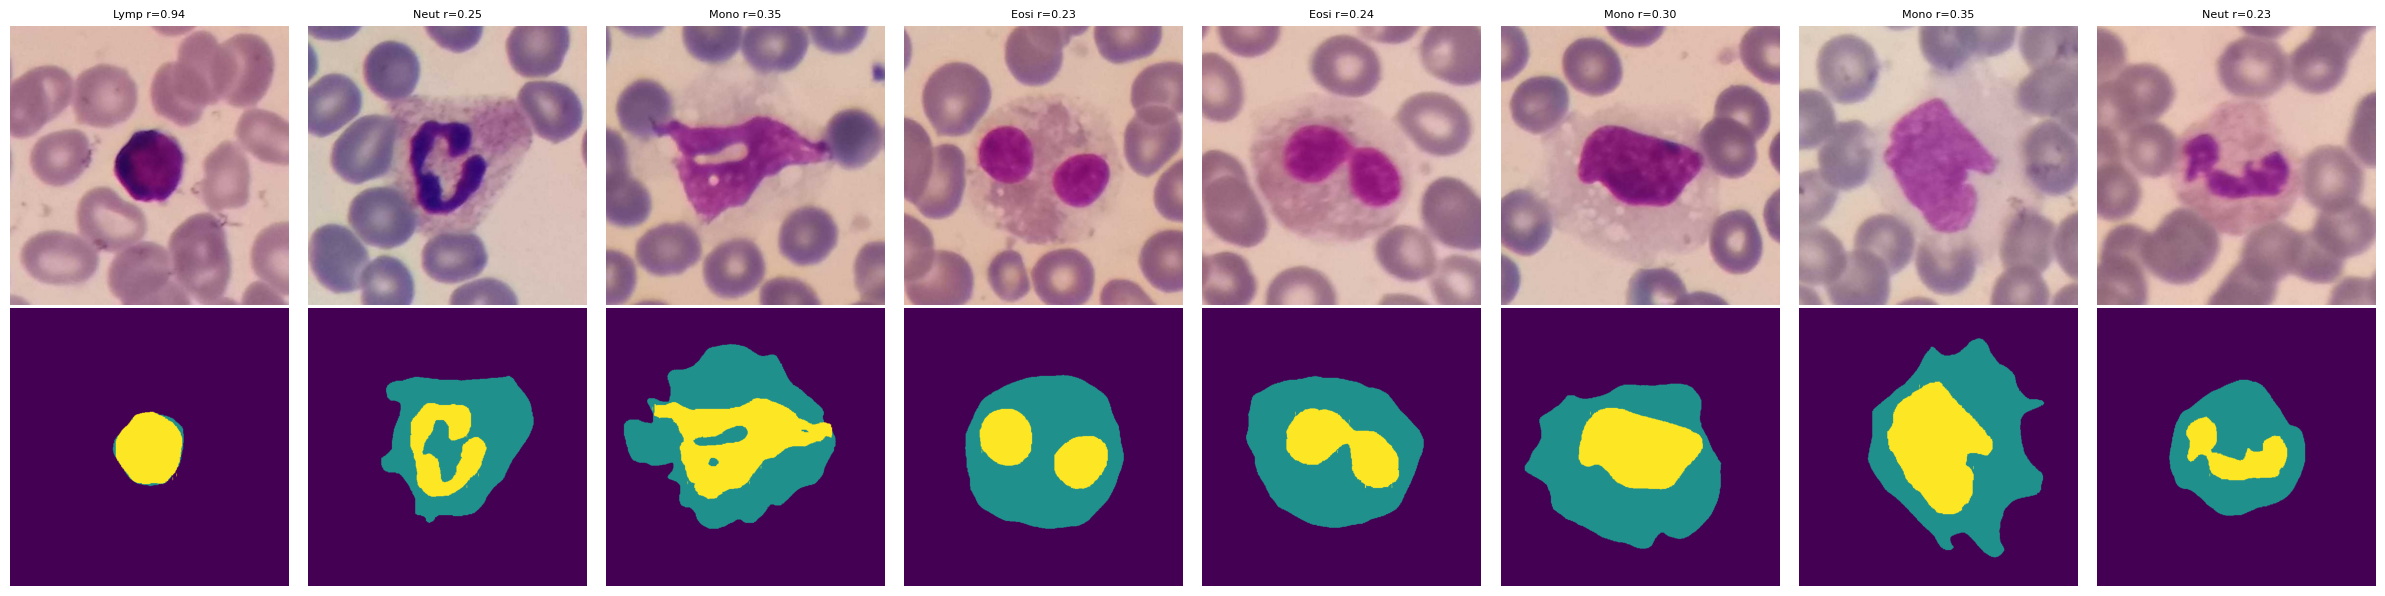

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# 1) Apusan terbesar dan posisinya di tiap split
big = eda.groupby("smear").size().sort_values(ascending=False)
print("Apusan terbesar:\n", big.head(4))
top2 = list(big.index[:2])
for name, parts in splits.items():
    for p, d in parts.items():
        print(f"[{name}/{p}] n={len(d):4d} | porsi dari 2 apusan terbesar: {d.smear.isin(top2).mean():.2f}")

# 2) Proporsi piksel (untuk Bab Data dan pembenaran loss)
tot = 575 * 575
print("\nProporsi piksel rata-rata per citra:")
print("  latar     :", round(float(1 - eda.frac_img.mean()), 3))
print("  sitoplasma:", round(float((eda.area_cyto / tot).mean()), 3))
print("  nukleus   :", round(float((eda.area_nuc / tot).mean()), 3))

# 3) Outlier mencolok: cek visual apakah anotasinya wajar
out = eda[(eda.area_cell > 100000) | (eda.nc_ratio > 0.9) | (eda.nc_ratio < 0.25)]
print("\nOutlier:", len(out))
print(out[["name", "cls", "area_cell", "nc_ratio"]].round(3).to_string())
sub = out.merge(df[["name", "img", "mask"]], on="name").head(8)
fig, ax = plt.subplots(2, len(sub), figsize=(3 * len(sub), 6), squeeze=False)
for k, r in enumerate(sub.itertuples()):
    ax[0, k].imshow(Image.open(r.img).convert("RGB")); ax[0, k].set_title(f"{r.cls[:4]} r={r.nc_ratio:.2f}", fontsize=8)
    ax[1, k].imshow(load_mask(r.mask), cmap="viridis", vmin=0, vmax=2)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

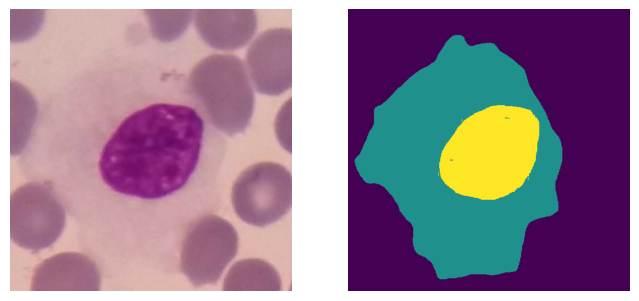

In [ ]:
r = df[df.name == "95-9-4-1_71_1.bmp"].iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(Image.open(r["img"]).convert("RGB"))
ax[1].imshow(load_mask(r["mask"]), cmap="viridis", vmin=0, vmax=2)
for a in ax: a.axis("off")
plt.show()

**Sel 10: Modul data**

In [ ]:
os.makedirs(f"{DRIVE}/code", exist_ok=True)
code = r'''
import os, numpy as np, pandas as pd, torch
from PIL import Image
from torch.utils.data import Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2

DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
BMP = "/content/raabin_gt/bmp"
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # normalisasi ImageNet

def load_split(scheme, part):
    # scheme: grouped | random | cross_session ; part: train | val | test
    return pd.read_csv(f"{DRIVE}/splits/{scheme}_{part}.csv")

def _path(name, mask):
    for s in ("Train", "Test"):
        p = f"{BMP}/{s}_GT_bmp/{name}" if mask else f"{BMP}/{s}_bmp/{name}"
        if os.path.exists(p): return p
    raise FileNotFoundError(name)

def make_tf(train, size=256, color_aug=True):
    t = [A.Resize(size, size)]
    if train:
        t += [A.HorizontalFlip(), A.VerticalFlip(), A.RandomRotate90()]
        if color_aug: t += [A.ColorJitter(0.2, 0.2, 0.2, 0.02, p=0.8)]
    t += [A.Normalize(MEAN, STD), ToTensorV2()]
    return A.Compose(t)

class WBCSeg(Dataset):
    # mask: 0=latar, 1=sitoplasma, 2=nukleus
    def __init__(self, df, train=False, size=256, color_aug=True):
        self.names = df["name"].tolist(); self.tf = make_tf(train, size, color_aug)
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        x = np.array(Image.open(_path(n, False)).convert("RGB"))
        m = np.array(Image.open(_path(n, True)))
        if m.ndim == 3: m = m[..., 0]
        y = np.zeros(m.shape, np.uint8); y[m == 255] = 1; y[m == 100] = 2
        o = self.tf(image=x, mask=y)
        return o["image"], o["mask"].long(), n
'''
open(f"{DRIVE}/code/data.py", "w").write(code)
print("Tersimpan:", f"{DRIVE}/code/data.py")

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/code/data.py


**Penyimpanan runlog**

In [ ]:
import os
DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
os.makedirs(f"{DRIVE}/code", exist_ok=True)

code = r'''
import os, time, datetime, pandas as pd, torch

DRIVE  = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
LOGDIR = f"{DRIVE}/logs"; os.makedirs(LOGDIR, exist_ok=True)

class RunLog:
    """Mencatat satu run ke log_<owner>.csv, termasuk run yang gagal dan durasi GPU."""
    def __init__(self, owner, **config):
        ts = datetime.datetime.now().strftime("%m%d_%H%M%S")
        self.row = dict(run_id=f"{owner}_{ts}", owner=owner, **config)

    def __enter__(self):
        self.t0 = time.time()
        self.row["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
        return self

    def metrics(self, **m):
        self.row.update(m)

    def __exit__(self, et, ev, tb):
        self.row["gpu_minutes"] = round((time.time() - self.t0) / 60, 2)
        self.row["status"] = "failed" if et else "ok"
        if et: self.row["notes"] = f"{et.__name__}: {str(ev)[:150]}"
        path = f"{LOGDIR}/log_{self.row['owner']}.csv"
        old = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
        pd.concat([old, pd.DataFrame([self.row])]).to_csv(path, index=False)
        return False
'''
open(f"{DRIVE}/code/runlog.py", "w").write(code)
print("Tersimpan:", f"{DRIVE}/code/runlog.py")

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/code/runlog.py
